# Eksploracja danych · Laboratorium 6
## Analiza koszyka: reguły asocjacyjne

Sklep osiedlowy EconoShop Express, paragony z września i października 2026 r. (dane syntetyczne). Pytanie kierownika: **które produkty kupowane są razem i co z tym zrobić** (ułożenie półek, oferta „kupujący X biorą też Y”, promocje)?

**Najpierw** uzupełnij TODO 1–3 w `koszyk.py` i uruchom w terminalu `pytest -q` (cel: `7 passed`). Potem uruchamiaj komórki po kolei (Shift + Enter). Luki `___` w komórkach uzupełnij przed uruchomieniem.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import koszyk as k

df = k.wczytaj("dane/paragony.csv")          # jeden wiersz = jeden produkt na paragonie
K = k.macierz_koszykow(df)                    # paragon × produkt: True / False
info = df.groupby("id_paragonu").agg(data=("data", "first"), godzina=("godzina", "first")).reindex(K.index)
pd.set_option("display.precision", 3)

def para(A, B, K=K):
    """Wszystkie miary reguły A → B w jednym wierszu."""
    return {"A": A, "B": B, "paragony z A": k.liczba(K, A), "paragony z A i B": k.liczba(K, [A, B]),
            "wsparcie A i B": round(k.wsparcie(K, [A, B]), 4), "pewność": round(k.pewnosc(K, A, B), 3),
            "wsparcie B": round(k.wsparcie(K, B), 3), "lift": round(k.lift(K, A, B), 2)}

## Z1. Dane: ile paragonów, ile produktów, co jest popularne

wierszy: 26970  paragonów: 7968  produktów: 34
średnio produktów na paragonie: 3.38


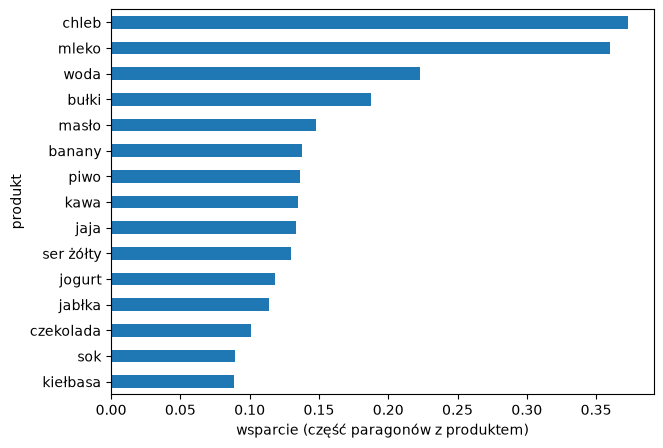

produkt
chleb    0.373
mleko    0.360
woda     0.223
bułki    0.187
masło    0.148
dtype: float64

In [2]:
print("wierszy:", len(df), " paragonów:", K.shape[0], " produktów:", K.shape[1])
print("średnio produktów na paragonie:", round(K.sum(axis=1).mean(), 2))
wsp = K.mean().sort_values(ascending=False)       # wsparcie każdego produktu
wsp.head(15).plot(kind="barh", figsize=(7, 5)).invert_yaxis()
plt.xlabel("wsparcie (część paragonów z produktem)"); plt.show()
wsp.head(5)

**Pytanie:** dwa produkty są na ponad jednej trzeciej paragonów. Co to oznacza dla reguły „cokolwiek → chleb”: czy wysoka pewność takiej reguły coś mówi?

**Odpowiedź:** Chleb występuje na 37,3% paragonów, a mleko na 36,0%, więc są to bardzo popularne produkty. Wysoka pewność reguły „cokolwiek → chleb” nie musi oznaczać silnego związku między produktami. Należy sprawdzić również lift. Jeśli jest bliski 1, zakup pierwszego produktu nie zwiększa istotnie prawdopodobieństwa zakupu chleba.

## Z2. Trzy miary na wybranych parach

Najpierw jedna reguła „ręcznie” (licząc paragony), potem tabela dla kilku par.

In [3]:
nA = k.liczba(K, "makaron")                         # paragony z makaronem
nAB = k.liczba(K, ["makaron", "sos pomidorowy"])    # paragony z makaronem i sosem
nB = k.liczba(K, "sos pomidorowy")
n = len(K)
pewnosc_recznie = nAB / nA                         # odsetek paragonow z makaronem, na ktorych jest sos
lift_recznie = pewnosc_recznie / (nB / n)          # w porownaniu z popularnoscia sosu
print(nA, nAB, nB, round(pewnosc_recznie, 3), round(lift_recznie, 2))

664 207 416 0.312 5.97


In [4]:
pary = [("makaron", "sos pomidorowy"), ("sos pomidorowy", "makaron"), ("kawa", "mleko"),
        ("pieluchy", "chusteczki nawilżane"), ("masło", "chleb"), ("mleko", "chleb")]
pd.DataFrame([para(A, B) for A, B in pary])

,A,B,paragony z A,paragony z A i B,wsparcie A i B,pewność,wsparcie B,lift
0,makaron,sos pomidorowy,664,207,0.026,0.312,0.052,5.97
1,sos pomidorowy,makaron,416,207,0.026,0.498,0.083,5.97
2,kawa,mleko,1077,498,0.062,0.462,0.360,1.28
3,pieluchy,chusteczki nawilżane,352,108,0.014,0.307,0.048,6.33
4,masło,chleb,1178,682,0.086,0.579,0.373,1.55
5,mleko,chleb,2868,1144,0.144,0.399,0.373,1.07


**Pytania:** (1) Dlaczego pewność makaron → sos jest inna niż sos → makaron, a lift ten sam? (2) Kawa → mleko ma pewność 0,46, a lift tylko 1,28. Mleko → chleb: pewność 0,40, lift 1,07. Która z tych par to prawdziwy związek, a która głównie popularność następnika?

**Odpowiedź:** (1) Pewność jest różna, ponieważ zmienia się mianownik: makaron → sos pomidorowy to 207/664 = 0,312, natomiast sos pomidorowy → makaron to 207/416 = 0,498. Lift jest taki sam (5,97), ponieważ mierzy współwystępowanie obu produktów względem ich popularności i jest symetryczny dla pary produktów.

(2) Kawa → mleko (pewność 0,462, lift 1,28) wskazuje na umiarkowany dodatni związek: przy zakupie kawy mleko występuje częściej niż przeciętnie. Mleko → chleb (pewność 0,399, lift 1,07) to przede wszystkim efekt popularności chleba (obecnego na 37,3% wszystkich paragonów); związek jest bardzo słaby.

## Z3. Algorytm Apriori: wszystkie reguły naraz

Funkcja `k.reguly` szuka zbiorów produktów, które występują razem na co najmniej `min_wsparcie` paragonów, i tworzy z nich reguły. Ustaw próg 1% paragonów.

In [5]:
r = k.reguly(K, min_wsparcie=0.01, min_lift=1.0)    # 1% paragonów = 0.01
print("reguł:", len(r), " z lift >= 1,2:", (r.lift >= 1.2).sum(), " z lift >= 2:", (r.lift >= 2).sum())
r.head(10)

reguł: 540  z lift >= 1,2: 246  z lift >= 2: 86


,poprzednik,nastepnik,wsparcie,pewnosc,lift,paragony
0,kiełbasa + piwo,węgiel drzewny,0.012,0.460,22.491,98
1,węgiel drzewny,kiełbasa + piwo,0.012,0.601,22.491,98
2,makaron + sos pomidorowy,parmezan,0.011,0.440,19.353,91
3,parmezan,makaron + sos pomidorowy,0.011,0.503,19.353,91
4,makaron + parmezan,sos pomidorowy,0.011,0.843,16.139,91
5,sos pomidorowy,makaron + parmezan,0.011,0.219,16.139,91
6,makaron,parmezan + sos pomidorowy,0.011,0.137,11.617,91
7,parmezan + sos pomidorowy,makaron,0.011,0.968,11.617,91
8,sos pomidorowy,parmezan,0.012,0.226,9.947,94
9,parmezan,sos pomidorowy,0.012,0.519,9.947,94


In [6]:
# kontrola: Apriori (biblioteka mlxtend) i nasze funkcje dają to samo
w = r[(r.poprzednik == "makaron") & (r.nastepnik == "sos pomidorowy")].iloc[0]
print(round(w.pewnosc, 4), round(k.pewnosc(K, "makaron", "sos pomidorowy"), 4), round(w.lift, 4), round(k.lift(K, "makaron", "sos pomidorowy"), 4))

0.3117 0.3117 5.9712 5.9712


In [7]:
# reguły z wysoką pewnością, ale liftem bliskim 1: „popularny następnik”
pop = r[(r.pewnosc >= 0.3) & (r.lift < 1.1)]
print("takich reguł:", len(pop)); pop.head(6)

takich reguł: 35


,poprzednik,nastepnik,wsparcie,pewnosc,lift,paragony
331,płatki,mleko,0.021,0.392,1.090,166
356,banany + mleko,chleb,0.020,0.401,1.077,163
358,kawa + mleko,chleb,0.025,0.400,1.072,199
360,mleko,chleb,0.144,0.399,1.070,1144
361,chleb,mleko,0.144,0.385,1.070,1144
371,pieluchy,mleko,0.017,0.384,1.066,135


**Pytanie:** reguł z liftem ≥ 1 jest kilkaset. Które trzy wybrałbyś do rozmowy z kierownikiem sklepu i dlaczego (wsparcie, lift, czy to nie dwa zapisy tej samej zależności)?

**Odpowiedź:** Do rozmowy z kierownikiem wybrałbym trzy reguły dotyczące różnych sytuacji zakupowych, zamiast powtarzać tę samą zależność w obu kierunkach:

1. **Makaron → sos pomidorowy:** 207 wspólnych paragonów (wsparcie 2,60%), pewność 0,312, lift 5,97. Warto przetestować ustawienie sosu obok makaronu.
2. **Pieluchy → chusteczki nawilżane:** 108 wspólnych paragonów (wsparcie 1,36%), pewność 0,307, lift 6,33. Warto przetestować ekspozycję chusteczek w pobliżu pieluch.
3. **Kiełbasa → musztarda:** 119 wspólnych paragonów (wsparcie 1,49%), pewność 0,169, lift 3,72. Można testować zestawienie produktów, ale najpierw sprawdzić sezonowość tej reguły.

Wszystkie trzy pary spełniają próg wsparcia 1% i mają lift wyraźnie większy niż 1, lecz sama reguła nie dowodzi, że zmiana ekspozycji spowoduje wzrost sprzedaży. Nie traktuję reguł odwrotnych jako trzech odrębnych pomysłów.


## Z4. Cztery pułapki

### a) Próg wsparcia: za niski daje tysiące reguł i przypadkowe rekordy

In [8]:
for ms in [0.0003, 0.001, 0.003, 0.01, 0.02, 0.05]:
    rr = k.reguly(K, min_wsparcie=ms, min_lift=1.0)
    print(f"min wsparcie {ms:>7}: reguł {len(rr):>6}   najwyższy lift: {rr.poprzednik[0]} → {rr.nastepnik[0]}, lift {rr.lift[0]:.1f}, paragonów {rr.paragony[0]}")

min wsparcie  0.0003: reguł  13698   najwyższy lift: kawior → szampan, lift 177.1, paragonów 3
min wsparcie   0.001: reguł   8172   najwyższy lift: kiełbasa + musztarda → węgiel drzewny, lift 24.6, paragonów 60
min wsparcie   0.003: reguł   2858   najwyższy lift: kiełbasa + musztarda → węgiel drzewny, lift 24.6, paragonów 60
min wsparcie    0.01: reguł    540   najwyższy lift: kiełbasa + piwo → węgiel drzewny, lift 22.5, paragonów 98
min wsparcie    0.02: reguł    162   najwyższy lift: makaron → sos pomidorowy, lift 6.0, paragonów 207
min wsparcie    0.05: reguł     22   najwyższy lift: chleb → masło, lift 1.6, paragonów 682


### b) Ile „reguł” powstaje z czystego przypadku?
Przemieszamy losowo każdą kolumnę: popularność produktów zostaje, związki między nimi znikają.

In [9]:
import numpy as np
rng = np.random.default_rng(0)
Kp = K.apply(lambda c: pd.Series(rng.permutation(c.values), index=K.index))
rp = k.reguly(Kp, min_wsparcie=0.01, min_lift=1.0)
print("reguł po przemieszaniu:", len(rp), " z lift >= 1,2:", (rp.lift >= 1.2).sum(), " najwyższy lift:", round(rp.lift.max(), 2))

reguł po przemieszaniu: 332  z lift >= 1,2: 6  najwyższy lift: 1.25


### c) Pieluchy i piwo: zależy od godziny
Uzupełnij maskę: paragony z godzin 17–19 (kolumna `info.godzina`).

In [10]:
okno = info.godzina.between(17, 19)
print("wszystkie:", para("pieluchy", "piwo"))
print("17–19:    ", para("pieluchy", "piwo", K[okno]))
print("inne:     ", para("pieluchy", "piwo", K[~okno]))

wszystkie: {'A': 'pieluchy', 'B': 'piwo', 'paragony z A': 352, 'paragony z A i B': 74, 'wsparcie A i B': 0.0093, 'pewność': 0.21, 'wsparcie B': 0.137, 'lift': 1.54}
17–19:     {'A': 'pieluchy', 'B': 'piwo', 'paragony z A': 104, 'paragony z A i B': 41, 'wsparcie A i B': 0.0171, 'pewność': 0.394, 'wsparcie B': 0.134, 'lift': 2.95}
inne:      {'A': 'pieluchy', 'B': 'piwo', 'paragony z A': 248, 'paragony z A i B': 33, 'wsparcie A i B': 0.0059, 'pewność': 0.133, 'wsparcie B': 0.138, 'lift': 0.97}


### d) Grill: wrzesień i październik

In [11]:
for m, nazwa in [(9, "wrzesień"), (10, "październik")]:
    Km = K[info.data.dt.month == m]
    print(nazwa, para("węgiel drzewny", "kiełbasa", Km))

wrzesień {'A': 'węgiel drzewny', 'B': 'kiełbasa', 'paragony z A': 148, 'paragony z A i B': 117, 'wsparcie A i B': 0.0296, 'pewność': 0.791, 'wsparcie B': 0.114, 'lift': 6.94}
październik {'A': 'węgiel drzewny', 'B': 'kiełbasa', 'paragony z A': 15, 'paragony z A i B': 2, 'wsparcie A i B': 0.0005, 'pewność': 0.133, 'wsparcie B': 0.063, 'lift': 2.1}


**Pytania:** (1) Co pokazał test z przemieszaniem? (2) Czy reguła pieluchy → piwo „istnieje”? (3) Czy reguła węgiel → kiełbasa ze stycznia przyszłego roku będzie aktualna?

**Odpowiedź:** (1) Po niezależnym przemieszaniu kolumn zachowujemy częstość poszczególnych produktów, ale usuwamy ich rzeczywiste współwystępowanie. Mimo tego otrzymujemy **332 reguły** z liftem ≥ 1, w tym **6 reguł** z liftem ≥ 1,2, a najwyższy lift wynosi tylko **1,25**. To dowodzi, że część pozornych zależności może powstawać przypadkowo; wyniki bliskie 1 należy interpretować ostrożnie.

(2) Reguła **pieluchy → piwo** jest zależna od pory dnia: dla całego okresu lift wynosi **1,54** (74 wspólne paragony), w godzinach **17:00–19:59** wynosi **2,95** (41 wspólnych paragonów), a poza tym oknem tylko **0,97** (33 wspólne paragony). Silny dodatni związek dotyczy więc określonych godzin, nie całego dnia. To hipoteza do testu, a nie dowód, że ekspozycja piwa zwiększy sprzedaż.

(3) Reguły **węgiel drzewny → kiełbasa** nie można przenosić automatycznie na styczeń 2027 r. We wrześniu produkty były razem na **117 paragonach** (lift **6,94**), natomiast w październiku tylko na **2** (lift **2,10**). Dane nie obejmują stycznia; przed decyzją potrzebne są nowe dane i sprawdzenie sezonowości.


## Z5. Od reguły do decyzji: ekspozycja czy rabat?

Pomysł 1: postawić sos pomidorowy obok makaronu (koszt ≈ 0 zł). Pomysł 2: rabat 20% na sos dla kupujących makaron.
Założenia (do dyskusji!): marża na sosie 30% ceny 6,99 zł, czyli 2,10 zł; rabat 1,40 zł; 5% klientów z makaronem, ale bez sosu, dokupi sos.

In [12]:
marza, rabat, konwersja = 2.10, 1.40, 0.05
p = k.potencjal(K, "makaron", "sos pomidorowy", konwersja, marza)
juz_razem = k.liczba(K, ["makaron", "sos pomidorowy"])        # i tak kupują oba
print(p, " juz_razem:", juz_razem)

zysk_ekspozycja = p["dodatkowa_marza_zl"]
koszt_rabatu_dla_juz_kupujacych = juz_razem * rabat
zysk_z_nowych_przy_rabacie = p["dodatkowe_sztuki"] * (marza - rabat)
wynik_rabatu = zysk_z_nowych_przy_rabacie - koszt_rabatu_dla_juz_kupujacych
print("ekspozycja:", round(zysk_ekspozycja, 2), "zł   rabat:", round(wynik_rabatu, 2), "zł   (dwa miesiące)")

{'paragony_z_A_bez_B': 457, 'dodatkowe_sztuki': 22.85, 'dodatkowa_marza_zl': 47.98500000000001}  juz_razem: 207
ekspozycja: 47.99 zł   rabat: -273.8 zł   (dwa miesiące)


In [13]:
# przy jakiej konwersji rabat wychodzi na zero?
konwersja_progu = koszt_rabatu_dla_juz_kupujacych / (p["paragony_z_A_bez_B"] * (marza - rabat))
print("rabat się zwraca dopiero przy konwersji:", round(konwersja_progu * 100, 1), "%")

rabat się zwraca dopiero przy konwersji: 90.6 %


**Pytania:** (1) Dlaczego silna reguła (lift ≈ 6) to argument przeciw rabatowi? (2) Reguła nie mówi, czy ekspozycja zwiększy sprzedaż sosu. Jak to sprawdzić, zanim zmienimy wszystkie sklepy?

**Odpowiedź:** (1) Reguła **makaron → sos pomidorowy** ma wysoki lift **5,97**, ale **207 z 664** klientów kupujących makaron już kupiło sos. Udzielenie im rabatu oznacza koszt **207 × 1,40 zł = 289,80 zł** nawet bez pozyskania nowego kupującego. Wśród **457** pozostałych paragonów zakładamy konwersję 5%, czyli 22,85 dodatkowego słoika. Ekspozycja przy marży 2,10 zł daje wtedy **+47,99 zł**, a rabat po uwzględnieniu kosztu dla dotychczasowych kupujących **−273,80 zł** w dwóch miesiącach; rabat wyszedłby na zero dopiero przy konwersji ok. **90,6%**. Są to wyniki scenariusza z założeniami, nie rzeczywisty przyrost sprzedaży.

(2) Aby sprawdzić skuteczność ekspozycji, przeprowadziłbym **4-tygodniowy test A/B**: losowo wybrane sklepy ustawią sos obok makaronu (grupa A), a pozostałe zachowają dotychczasowy układ (grupa B). Porównamy dodatkową sprzedaż sosu **na 100 paragonów z makaronem** oraz wynik marżowy przy podobnych warunkach (ceny, dostępność, sezon). Dopiero zaobserwowana różnica uzasadni wdrożenie w całej sieci.


## Z6. Dashboard na Render i rekomendacja (przygotowane do wdrożenia)

1. Dashboard Streamlit jest gotowy w `app.py`; lokalne uruchomienie w terminalu: `streamlit run app.py`.
2. `koszyk.py` ma uzupełnione TODO 1–3. Przed oddaniem wykonaj w JupyterLab **Kernel → Restart Kernel and Run All Cells**, następnie `pytest -q` (cel: **7 passed**) i zapisz notatnik.
3. Zapisz i wyślij pliki do repozytorium `analiza-koszyka` (`git add .`, `git commit`, `git push`); sprawdź zielony status w GitHub Actions.
4. Render: **New → Blueprint** → połącz repozytorium → **Deploy Blueprint**. Publicznego adresu nie można uzupełnić przed pomyślnym wdrożeniem.
5. Rekomendacja kierownicza (dwie reguły, jedna odrzucona i plan testu A/B) jest wpisana w `README.md`. **Po wdrożeniu wpisz rzeczywisty adres aplikacji do README.**
